       mfcc_1      mfcc_2     mfcc_3     mfcc_4     mfcc_5     mfcc_6  \
0 -526.897644   72.449478   5.072527  46.101234  -4.266626  20.942503   
1 -364.369232   79.014053 -43.645920  34.586338 -21.766678   9.554585   
2 -316.238770  110.025925 -58.451340  23.224773 -34.267723   7.718300   
3 -369.247253  101.039650 -58.050571  51.224083 -41.106976  34.982174   
4 -392.555725   67.871468 -67.595734  75.452087 -35.085106  42.816452   

      mfcc_7     mfcc_8     mfcc_9    mfcc_10    mfcc_11    mfcc_12   mfcc_13  \
0 -14.019300  20.847528  -7.395414  23.013361  -3.483970  15.531009 -5.815550   
1 -19.817905  29.331873  -6.413803  23.678139 -11.066226  11.929456 -4.668423   
2 -10.841154  34.754475  -4.005974  14.782266 -15.726407   9.186400 -1.458014   
3 -10.110136  39.319748 -15.551326  15.256783 -15.058349  14.896372 -0.642671   
4 -16.009180  37.192009 -21.242327  21.204597 -13.722758  16.570120 -1.807990   

      centroid    bandwidth   contrast       zcr label  
0  5609.735629  5

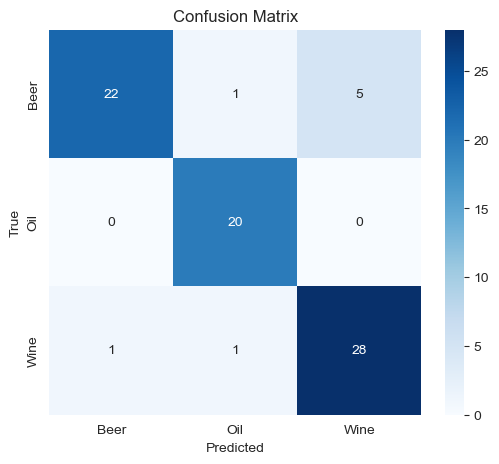

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load dataset ===
df = pd.read_csv("liquid_audio_features.csv")
print(df.head())

# === 2. Split features and labels ===
X = df.drop("label", axis=1).values
y = df["label"].values

# === 3. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# === 4. Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 5. Optional - Scale features ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 6. Train Classifier ===
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# === 7. Evaluate ===
y_pred = clf.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# === 8. Confusion Matrix ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
